In [1]:
# Cell 1: Environment Setup and Imports
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Notebook visual settings
pd.set_option("display.max_columns", 25)
%matplotlib inline

# Create output folders if running independently
os.makedirs("../data", exist_ok=True)
os.makedirs("../artifacts", exist_ok=True)

RANDOM_SEED = 42
CSV_PATH = "../data/iot_network_traffic.csv"
ARTIFACT_PATH = "../artifacts/iot_ids_artifacts.pkl"
METADATA_PATH = "../artifacts/model_metadata.json"
PLOT_PATH = "../artifacts/ids_model_evaluation.png"

FEATURES = [
    "Destination Port",
    "Protocol",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Mean",
    "Bwd Packet Length Mean",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "SYN Flag Count",
    "ACK Flag Count",
    "RST Flag Count",
]

print("✅ Setup complete.")
print(f"Python Version: {sys.version.split()[0]} | Scikit-Learn Version: {sklearn.__version__}")


✅ Setup complete.
Python Version: 3.14.0 | Scikit-Learn Version: 1.7.2


In [2]:
# Cell 2: Step 1 - Ingest Dataset or Generate Synthetic Data
def generate_synthetic_iot_traffic(n_samples=10000):
    """Generates synthetic benign IoT telemetry vs. attack flows if no external CSV is present."""
    np.random.seed(RANDOM_SEED)
    n_normal = int(n_samples * 0.65)
    n_attack = n_samples - n_normal

    normal_data = {
        "Destination Port": np.random.choice([80, 443, 1883, 53, 8883], n_normal, p=[0.2, 0.3, 0.3, 0.1, 0.1]),
        "Protocol": np.random.choice([6, 17], n_normal, p=[0.75, 0.25]),
        "Flow Duration": np.random.exponential(scale=45000, size=n_normal),
        "Total Fwd Packets": np.random.poisson(lam=8, size=n_normal) + 1,
        "Total Backward Packets": np.random.poisson(lam=7, size=n_normal) + 1,
        "Total Length of Fwd Packets": np.random.normal(loc=650, scale=200, size=n_normal).clip(40),
        "Total Length of Bwd Packets": np.random.normal(loc=800, scale=250, size=n_normal).clip(40),
        "Fwd Packet Length Mean": np.random.normal(loc=80, scale=20, size=n_normal).clip(20),
        "Bwd Packet Length Mean": np.random.normal(loc=110, scale=30, size=n_normal).clip(20),
        "Flow Bytes/s": np.random.normal(loc=15000, scale=5000, size=n_normal).clip(100),
        "Flow Packets/s": np.random.normal(loc=120, scale=40, size=n_normal).clip(5),
        "Flow IAT Mean": np.random.normal(loc=5500, scale=1500, size=n_normal).clip(100),
        "SYN Flag Count": np.random.choice([0, 1], n_normal, p=[0.3, 0.7]),
        "ACK Flag Count": np.random.choice([1, 2, 3], n_normal, p=[0.5, 0.3, 0.2]),
        "RST Flag Count": np.random.choice([0, 1], n_normal, p=[0.95, 0.05]),
        "Label": "BENIGN",
    }

    attack_data = {
        "Destination Port": np.random.choice([80, 1883, 22, 23, 8080], n_attack, p=[0.35, 0.3, 0.15, 0.1, 0.1]),
        "Protocol": np.random.choice([6, 17, 1], n_attack, p=[0.6, 0.3, 0.1]),
        "Flow Duration": np.random.exponential(scale=12000, size=n_attack),
        "Total Fwd Packets": np.random.poisson(lam=45, size=n_attack) + 5,
        "Total Backward Packets": np.random.poisson(lam=2, size=n_attack),
        "Total Length of Fwd Packets": np.random.normal(loc=4200, scale=1500, size=n_attack).clip(0),
        "Total Length of Bwd Packets": np.random.normal(loc=120, scale=80, size=n_attack).clip(0),
        "Fwd Packet Length Mean": np.random.normal(loc=95, scale=45, size=n_attack).clip(0),
        "Bwd Packet Length Mean": np.random.normal(loc=30, scale=25, size=n_attack).clip(0),
        "Flow Bytes/s": np.random.normal(loc=180000, scale=65000, size=n_attack).clip(500),
        "Flow Packets/s": np.random.normal(loc=2200, scale=800, size=n_attack).clip(50),
        "Flow IAT Mean": np.random.normal(loc=450, scale=300, size=n_attack).clip(1),
        "SYN Flag Count": np.random.choice([1, 2, 5, 10], n_attack, p=[0.2, 0.3, 0.3, 0.2]),
        "ACK Flag Count": np.random.choice([0, 1], n_attack, p=[0.8, 0.2]),
        "RST Flag Count": np.random.choice([0, 1, 2], n_attack, p=[0.4, 0.4, 0.2]),
        "Label": "ATTACK",
    }

    df_syn = pd.concat([pd.DataFrame(normal_data), pd.DataFrame(attack_data)], ignore_index=True)
    # Inject realistic 2.5% label noise
    flip_idx = np.random.choice(df_syn.index, size=int(0.025 * len(df_syn)), replace=False)
    df_syn.loc[flip_idx, "Label"] = df_syn.loc[flip_idx, "Label"].map({"BENIGN": "ATTACK", "ATTACK": "BENIGN"})
    return df_syn.sample(frac=1.0, random_state=RANDOM_SEED).reset_index(drop=True)

if os.path.exists(CSV_PATH):
    print(f"📂 Loading existing dataset from: '{CSV_PATH}'")
    df = pd.read_csv(CSV_PATH)
    df.columns = df.columns.str.strip()
else:
    print(f"⚠️ '{CSV_PATH}' not found. Synthesizing 10,000 realistic IoT network flows...")
    df = generate_synthetic_iot_traffic(n_samples=10000)
    df.to_csv(CSV_PATH, index=False)
    print(f"✅ Saved synthetic dataset to '{CSV_PATH}'.")

print(f"\nDataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nClass Distribution:")
print(df["Label"].value_counts())
df.head()


📂 Loading existing dataset from: '../data/iot_network_traffic.csv'

Dataset Shape: 10000 rows, 16 columns

Class Distribution:
Label
BENIGN    6436
ATTACK    3564
Name: count, dtype: int64


,Destination Port,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,SYN Flag Count,ACK Flag Count,RST Flag Count,Label
0,443,6,17332.943724,5,8,225.298041,718.215745,93.755141,104.564504,15369.424147,106.277752,7579.286290,1,3,0,BENIGN
1,1883,6,40252.141227,12,11,485.197989,983.274817,74.468780,111.762511,19919.963901,203.986239,5171.142086,1,3,0,BENIGN
2,1883,6,6028.402356,11,10,726.830046,597.524165,75.168834,126.183468,18291.593700,161.103291,4625.454350,1,1,0,BENIGN
3,80,6,49689.148709,9,9,442.186415,874.720187,87.402139,113.794768,14356.771763,92.157200,7448.336100,0,2,0,BENIGN
4,1883,6,40796.294001,9,11,578.764981,1014.843074,71.236883,103.399419,11700.759869,128.332902,4858.512372,1,1,0,BENIGN


In [3]:
# Cell 3: Step 2 - Data Sanitization & Feature Preparation
available_features = [col for col in FEATURES if col in df.columns]
X = df[available_features].copy()

# Privacy & ethics safeguard (Slide 16): drop host identifiers
privacy_sensitive_cols = ["Source IP", "Destination IP", "Timestamp", "Flow ID", "Src IP", "Dst IP"]
dropped_privacy_cols = [c for c in privacy_sensitive_cols if c in df.columns]
if dropped_privacy_cols:
    print(f"🔒 Data Privacy Safeguard: Stripped {dropped_privacy_cols} to prevent PII exposure and host overfitting.")

# Clean infinite values
X.replace([np.inf, -np.inf], np.nan, inplace=True)

# Binary target encoding: Normal (0) vs Attack (1)
y = df["Label"].astype(str).str.upper().apply(
    lambda val: 0 if ("BENIGN" in val or "NORMAL" in val) else 1
)

print(f"✅ Features Selected ({len(available_features)}): {available_features}")
print(f"Missing / Infinite values identified: {X.isna().sum().sum()}")
print(f"Target distribution -> Normal (0): {(y == 0).sum()} | Attack (1): {(y == 1).sum()}")


✅ Features Selected (15): ['Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'SYN Flag Count', 'ACK Flag Count', 'RST Flag Count']
Missing / Infinite values identified: 0
Target distribution -> Normal (0): 6436 | Attack (1): 3564


In [4]:
# Cell 4: Step 3 - Stratified Split & Leakage-Free Imputation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)

# Imputer is fitted strictly on X_train to prevent test data leakage
imputer = SimpleImputer(strategy="median")
X_train_clean = pd.DataFrame(imputer.fit_transform(X_train), columns=available_features)
X_test_clean = pd.DataFrame(imputer.transform(X_test), columns=available_features)

print(f"✅ Training set: {X_train_clean.shape[0]} flows (80%)")
print(f"✅ Testing set:  {X_test_clean.shape[0]} flows (20%) [Unseen evaluation partition]")


✅ Training set: 8000 flows (80%)
✅ Testing set:  2000 flows (20%) [Unseen evaluation partition]


In [5]:
# Cell 5: Step 4 - Model Training
# Baseline Model: Decision Tree Classifier (Slide 12)
dt_model = DecisionTreeClassifier(max_depth=8, random_state=RANDOM_SEED)
dt_model.fit(X_train_clean, y_train)
dt_preds = dt_model.predict(X_test_clean)

# Primary Model: Random Forest Classifier (Slide 12)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    class_weight="balanced",
    random_state=RANDOM_SEED,
    n_jobs=-1,
)
rf_model.fit(X_train_clean, y_train)
rf_preds = rf_model.predict(X_test_clean)

print("✅ Decision Tree (Baseline) and Random Forest (Primary) models trained successfully.")


✅ Decision Tree (Baseline) and Random Forest (Primary) models trained successfully.


=== IDS Model Performance Comparison (Unseen Test Partition) ===


,Accuracy,Precision,Recall (Detection Rate),F1-Score,False Positive Rate (FPR)
Decision Tree (Baseline),96.9000%,96.5665%,94.6704%,95.6091%,1.8648%
Random Forest (Primary),97.1000%,96.7190%,95.0912%,95.8982%,1.7871%



=== Random Forest Classification Report ===
                       precision    recall  f1-score   support

           Normal (0)       0.97      0.98      0.98      1287
Suspicious/Attack (1)       0.97      0.95      0.96       713

             accuracy                           0.97      2000
            macro avg       0.97      0.97      0.97      2000
         weighted avg       0.97      0.97      0.97      2000



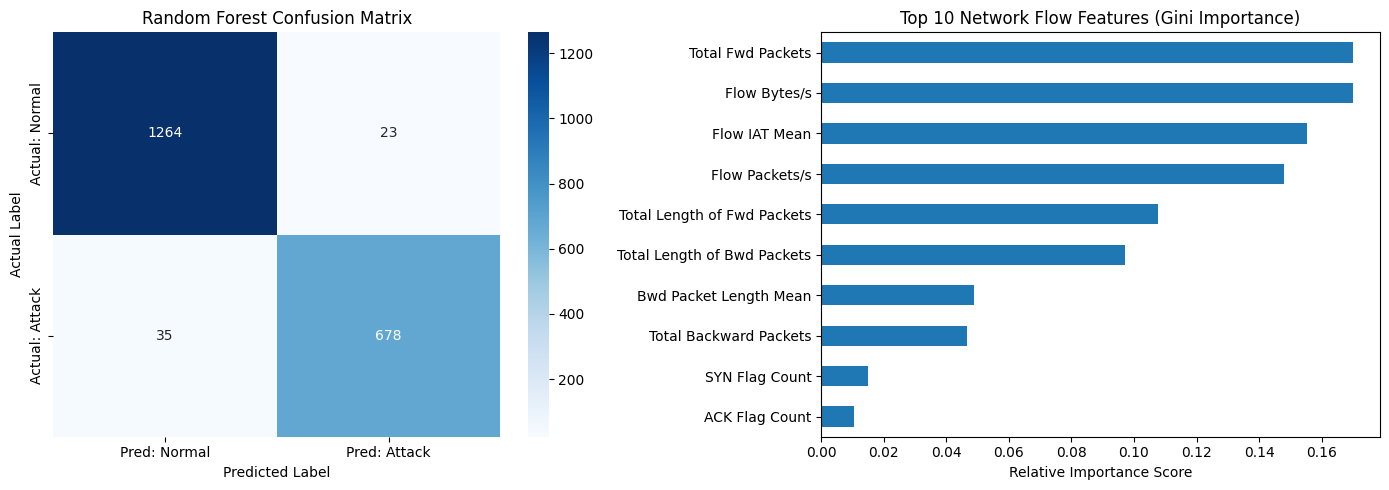


=== Sample Flow Inspection Predictions ===


,Actual_Status,Model_Verdict,Destination Port,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Mean,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,SYN Flag Count,ACK Flag Count,RST Flag Count
0,NORMAL,✅ NORMAL,80.0,6.0,24434.714409,6.0,13.0,514.707835,975.795334,96.679563,121.631748,13702.836603,191.196895,5597.835184,1.0,1.0,0.0
1,NORMAL,✅ NORMAL,443.0,6.0,20653.928279,9.0,9.0,1169.120704,1435.456301,60.483371,99.563336,14691.630463,66.187678,6661.110558,0.0,1.0,0.0
2,NORMAL,✅ NORMAL,443.0,6.0,24786.977885,12.0,6.0,576.832540,699.359467,64.832737,73.935630,9644.817657,71.718673,1742.454958,1.0,2.0,0.0
3,NORMAL,✅ NORMAL,80.0,6.0,56000.728217,13.0,10.0,584.426232,1058.698707,106.995777,128.511074,10063.554907,140.888733,6945.380546,0.0,1.0,0.0
4,NORMAL,✅ NORMAL,443.0,6.0,22774.095734,12.0,14.0,782.718666,1068.962204,81.599885,91.947080,11168.869888,163.723303,2706.287972,0.0,2.0,0.0
5,NORMAL,✅ NORMAL,443.0,6.0,994.214450,13.0,9.0,484.205065,762.397495,84.278695,105.763677,8639.286940,155.023895,4577.536153,1.0,1.0,0.0
6,NORMAL,✅ NORMAL,1883.0,6.0,2055.960502,14.0,4.0,268.422139,895.592127,104.875313,105.600305,13211.665089,71.135074,4987.870462,1.0,3.0,0.0
7,ATTACK,🚨 SUSPICIOUS,80.0,17.0,5276.409484,56.0,5.0,4868.757638,38.905848,50.773561,61.886430,148717.387826,2244.357940,210.294765,5.0,0.0,0.0
8,NORMAL,✅ NORMAL,443.0,6.0,75859.538491,9.0,6.0,511.428688,1063.778906,95.823344,117.737449,10843.737300,192.841879,3233.179061,1.0,1.0,0.0
9,NORMAL,✅ NORMAL,1883.0,6.0,12329.065382,6.0,8.0,603.093240,634.163602,62.453394,113.180526,10210.223499,107.283505,7239.757047,1.0,1.0,0.0


In [6]:
# Cell 6: Step 5 - Evaluation & Metrics Calculation (Includes FPR)
def compute_ids_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    # False Positive Rate = FP / (FP + TN)
    # Measures proportion of benign traffic falsely flagged as attack (False Alarms)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    return {
        "Accuracy": acc,
        "Precision": prec,
        "Recall (Detection Rate)": rec,
        "F1-Score": f1,
        "False Positive Rate (FPR)": fpr,
        "True Negatives (TN)": int(tn),
        "False Positives (FP)": int(fp),
        "False Negatives (FN)": int(fn),
        "True Positives (TP)": int(tp),
        "Confusion_Matrix": cm,
    }

metrics = {
    "Decision Tree (Baseline)": compute_ids_metrics(y_test, dt_preds),
    "Random Forest (Primary)": compute_ids_metrics(y_test, rf_preds),
}

comparison_df = pd.DataFrame(metrics).T[
    ["Accuracy", "Precision", "Recall (Detection Rate)", "F1-Score", "False Positive Rate (FPR)"]
]

print("=== IDS Model Performance Comparison (Unseen Test Partition) ===")
display(comparison_df.style.format("{:.4%}"))

print("\n=== Random Forest Classification Report ===")
print(classification_report(y_test, rf_preds, target_names=["Normal (0)", "Suspicious/Attack (1)"]))

# Visualizations: Confusion Matrix and Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    metrics["Random Forest (Primary)"]["Confusion_Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred: Normal", "Pred: Attack"],
    yticklabels=["Actual: Normal", "Actual: Attack"],
    ax=axes[0],
)
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

importances = pd.Series(rf_model.feature_importances_, index=available_features).sort_values(ascending=True)
importances.tail(10).plot(kind="barh", color="#1f77b4", ax=axes[1])
axes[1].set_title("Top 10 Network Flow Features (Gini Importance)")
axes[1].set_xlabel("Relative Importance Score")

plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=200)
plt.show()

# Sample flow predictions inspection
sample_inspect = X_test_clean.iloc[:10].copy()
sample_inspect.insert(0, "Actual_Status", np.where(y_test.iloc[:10] == 1, "ATTACK", "NORMAL"))
sample_inspect.insert(1, "Model_Verdict", np.where(rf_preds[:10] == 1, "🚨 SUSPICIOUS", "✅ NORMAL"))
print("\n=== Sample Flow Inspection Predictions ===")
display(sample_inspect.head(10))


In [7]:
# Cell 7: Step 6 - Reproducibility Metadata & Artifact Serialization
# 1. Build Reproducibility Manifest (Slide 12 Requirement)
metadata = {
    "project_title": "AI-Based IoT Network Attack Detection",
    "institution": "Unitedworld Institute of Technology, Karnavati University",
    "course": "Computer Networks",
    "faculty_guide": "Ms. Pragya Vats",
    "random_seed": RANDOM_SEED,
    "train_test_split": "80/20 Stratified",
    "dataset_source": CSV_PATH,
    "total_samples": int(df.shape[0]),
    "features_used": available_features,
    "software_versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "model_hyperparameters": {
        "baseline_decision_tree": {"max_depth": 8},
        "primary_random_forest": {"n_estimators": 100, "max_depth": 15, "class_weight": "balanced"},
    },
    "measured_results_rf": {
        "accuracy": float(metrics["Random Forest (Primary)"]["Accuracy"]),
        "precision": float(metrics["Random Forest (Primary)"]["Precision"]),
        "recall": float(metrics["Random Forest (Primary)"]["Recall (Detection Rate)"]),
        "f1_score": float(metrics["Random Forest (Primary)"]["F1-Score"]),
        "false_positive_rate": float(metrics["Random Forest (Primary)"]["False Positive Rate (FPR)"]),
    },
}

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=4)
print(f"📋 Reproducibility metadata exported to '{METADATA_PATH}'.")

# 2. Save Trained Binary Artifacts for Streamlit Dashboard
artifacts = {
    "rf_model": rf_model,
    "dt_model": dt_model,
    "imputer": imputer,
    "features": available_features,
    "metrics": metrics,
    "feature_importances": importances.sort_values(ascending=False),
    "sample_test_data": X_test_clean.iloc[:200].assign(Actual_Label=y_test.iloc[:200].values),
}
joblib.dump(artifacts, ARTIFACT_PATH)
print(f"🎉 Model artifact bundle saved to '{ARTIFACT_PATH}'. Ready for 'streamlit run src/app.py'!")


📋 Reproducibility metadata exported to '../artifacts/model_metadata.json'.
🎉 Model artifact bundle saved to '../artifacts/iot_ids_artifacts.pkl'. Ready for 'streamlit run src/app.py'!
